# 03 – Time-aware validation and baseline models

**Group:** 119  
**Kaggle team:** [119] SINTEF Databreach  
**Member:** Henrik Remmen (541747)

This notebook establishes the fixed local evaluation protocol and compares three baselines:

1. smoothed historical ON-rate by unit, month, and hour;
2. logistic regression with the 20 baseline features;
3. one LightGBM classifier per generating unit.

The notebook is intentionally not pre-executed because model fitting can take time.


## 1. Evaluation protocol

The hidden test labels are split chronologically: public Kaggle uses 2023 and private Kaggle uses 2024. Local validation must therefore mimic prediction of a future year.

The folds are:

- train through 2019, validate 2020;
- train through 2020, validate 2021;
- train through 2021, validate 2022.

A training case is allowed only when its complete 168-hour target horizon ends before the validation year starts. This purges overlapping schedules at the boundary. Model selection uses mean and worst-fold micro ROC-AUC, not the public leaderboard alone.


In [3]:
from pathlib import Path
import re
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
SUBMISSION_DIR = ROOT / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
HORIZON = 168
N_JOBS = 4

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


## 2. Load the supplied data


In [4]:
def read_time_csv(path, time_column="date"):
    df = pd.read_csv(path)
    df[time_column] = pd.to_datetime(df[time_column], utc=True)
    return df

price = read_time_csv(DATA_DIR/"kernel"/"Historical_day_ahead_price_2015_2025.csv")
inflow = read_time_csv(DATA_DIR/"kernel"/"Historical_inflow_1958_2025.csv")
volume = read_time_csv(DATA_DIR/"kernel"/"Historical_volume_2015_2024.csv")
water_value = read_time_csv(DATA_DIR/"kernel"/"Synthetic_water_value_2015_2024.csv")
min_flow = read_time_csv(DATA_DIR/"extended"/"Constraint_min_flow.csv")
min_volume = read_time_csv(DATA_DIR/"extended"/"Constraint_min_volume.csv")
target_df = read_time_csv(DATA_DIR/"kernel"/"Unit_commitment_decisions.csv", "starttime")
prediction_mapping = read_time_csv(ROOT/"prediction_mapping.csv", "starttime")
sample_submission = pd.read_csv(ROOT/"sample_submission.csv")

with open(DATA_DIR/"extended"/"Tokke_Vinje_topology.yaml") as stream:
    topology = yaml.safe_load(stream)

target_pattern = re.compile(r"^result_committed_(.+)_t(\d+)$")
target_columns = [c for c in target_df if target_pattern.match(c)]
units = list(dict.fromkeys(target_pattern.match(c).group(1) for c in target_columns))

assert len(units) == 14
assert len(target_columns) == 14*HORIZON
assert target_columns == list(sample_submission.columns[1:])
assert set(np.unique(target_df[target_columns].to_numpy())).issubset({0, 1})

target_cube = np.stack([
    target_df[[f"result_committed_{unit}_t{h}" for h in range(HORIZON)]]
    .to_numpy(dtype=np.int8)
    for unit in units
], axis=1)

train_cases = target_df[["Run No", "starttime"]].copy()
test_cases = prediction_mapping[["Run No", "starttime"]].copy()
all_cases = pd.concat([
    train_cases.assign(split="train"),
    test_cases.assign(split="test"),
], ignore_index=True)

N_TRAIN_CASES = len(train_cases)
N_TEST_CASES = len(test_cases)
N_ALL_CASES = len(all_cases)

print("Target cube:", target_cube.shape)
print(f"Cases: {N_TRAIN_CASES:,} train + {N_TEST_CASES:,} test")


Target cube: (2922, 14, 168)
Cases: 2,922 train + 725 test


## 3. Construct the compact 20-feature baseline matrix

This repeats the baseline subset defined in `02_feature_engineering.ipynb` so the notebook remains self-contained. Scaling is not applied here: logistic regression fits a scaler inside each training fold, while LightGBM does not require normalisation.


In [5]:
def numeric_indexed(df):
    return df.set_index("date").select_dtypes(include=np.number)

all_starts = pd.DatetimeIndex(all_cases["starttime"])
case_index = np.repeat(np.arange(N_ALL_CASES), HORIZON)
horizon_hour = np.tile(np.arange(HORIZON), N_ALL_CASES)
target_time = pd.DatetimeIndex(
    all_starts.repeat(HORIZON)
    + pd.to_timedelta(horizon_hour, unit="h")
)

def hourly_matrix(series):
    values = series.reindex(target_time).to_numpy()
    matrix = values.reshape(N_ALL_CASES, HORIZON)
    if not np.isfinite(matrix).all():
        raise ValueError(f"Missing/non-finite hourly inputs: {(~np.isfinite(matrix)).sum()}")
    return matrix

def repeat_case(values):
    values = np.asarray(values)
    assert len(values) == N_ALL_CASES
    return np.repeat(values, HORIZON)

def cyclic(values, period):
    angle = 2*np.pi*np.asarray(values)/period
    return np.sin(angle), np.cos(angle)

def centred_rolling_mean(matrix, window):
    return (
        pd.DataFrame(matrix).T
        .rolling(window=window, min_periods=1, center=True)
        .mean().T.to_numpy()
    )

feature_data = {}

hour = target_time.hour.to_numpy()
weekday = target_time.dayofweek.to_numpy()
month = target_time.month.to_numpy()
feature_data["hour_sin"], feature_data["hour_cos"] = cyclic(hour, 24)
feature_data["weekday_sin"], feature_data["weekday_cos"] = cyclic(weekday, 7)
feature_data["month_sin"], feature_data["month_cos"] = cyclic(month-1, 12)
feature_data["horizon_hour"] = horizon_hour

price_matrix = hourly_matrix(
    price.set_index("date")["Day-ahead price (EUR/MWh)"]
)
price_week_mean = price_matrix.mean(axis=1)
price_week_std = price_matrix.std(axis=1)
price_rank = pd.DataFrame(price_matrix).rank(axis=1, pct=True).to_numpy()

feature_data["price"] = price_matrix.ravel()
feature_data["price_week_mean"] = repeat_case(price_week_mean)
feature_data["price_week_std"] = repeat_case(price_week_std)
feature_data["price_week_percentile"] = price_rank.ravel()
feature_data["price_minus_week_mean"] = (
    price_matrix-price_week_mean[:, None]
).ravel()

reservoirs = [c for c in volume.columns if c != "date"]
end_dates = all_starts + pd.Timedelta(days=7)
water_value_end = numeric_indexed(water_value).reindex(end_dates)[reservoirs]
water_value_end_mean = water_value_end.mean(axis=1).to_numpy()
feature_data["water_value_end_mean"] = repeat_case(water_value_end_mean)
feature_data["price_minus_water_value_mean"] = (
    price_matrix-water_value_end_mean[:, None]
).ravel()

capacity = {
    name: values["max_vol"]
    for name, values in topology["model"]["reservoir"].items()
}
start_volume = numeric_indexed(volume).reindex(all_starts)[reservoirs]
system_filling_ratio = (
    start_volume.sum(axis=1).to_numpy()
    / sum(capacity[r] for r in reservoirs)
)
feature_data["system_filling_ratio"] = repeat_case(system_filling_ratio)

inflow_total_matrix = hourly_matrix(numeric_indexed(inflow).sum(axis=1))
feature_data["inflow_total"] = inflow_total_matrix.ravel()
feature_data["inflow_total_24h_mean"] = (
    centred_rolling_mean(inflow_total_matrix, 24).ravel()
)

min_flow_matrix = hourly_matrix(numeric_indexed(min_flow).sum(axis=1))
min_volume_matrix = hourly_matrix(numeric_indexed(min_volume).sum(axis=1))
feature_data["min_flow_total"] = min_flow_matrix.ravel()
feature_data["min_volume_total"] = min_volume_matrix.ravel()

def variable_constraint_series(df):
    values = numeric_indexed(df)
    positive = values > 0
    rate = positive.mean(axis=0)
    columns = rate[(rate > 0) & (rate < 1)].index
    return positive[columns].any(axis=1)

variable_active_series = (
    variable_constraint_series(min_flow)
    | variable_constraint_series(min_volume)
)
variable_constraint_matrix = hourly_matrix(
    variable_active_series.astype(float)
)
feature_data["variable_constraint_active"] = variable_constraint_matrix.ravel()

BASELINE_FEATURES = [
    "hour_sin", "hour_cos", "weekday_sin", "weekday_cos",
    "month_sin", "month_cos", "horizon_hour",
    "price", "price_week_mean", "price_week_std",
    "price_week_percentile", "price_minus_week_mean",
    "water_value_end_mean", "price_minus_water_value_mean",
    "system_filling_ratio", "inflow_total",
    "inflow_total_24h_mean", "min_flow_total",
    "min_volume_total", "variable_constraint_active",
]

X_all = pd.DataFrame({
    name: np.asarray(feature_data[name], dtype=np.float32)
    for name in BASELINE_FEATURES
})

assert X_all.shape == (N_ALL_CASES*HORIZON, len(BASELINE_FEATURES))
assert not X_all.isna().any().any()
assert np.isfinite(X_all.to_numpy()).all()

print("Feature matrix:", X_all.shape)
display(X_all.head())


Feature matrix: (612696, 20)


,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,horizon_hour,price,price_week_mean,price_week_std,price_week_percentile,price_minus_week_mean,water_value_end_mean,price_minus_water_value_mean,system_filling_ratio,inflow_total,inflow_total_24h_mean,min_flow_total,min_volume_total,variable_constraint_active
0,0.000000,1.000000,0.433884,-0.900969,0.0,1.0,0.0,27.070000,28.980476,3.902484,0.247024,-1.910476,22.38294,4.687059,0.744351,45.900002,48.172501,10.8,0.0,0.0
1,0.258819,0.965926,0.433884,-0.900969,0.0,1.0,1.0,26.930000,28.980476,3.902484,0.166667,-2.050476,22.38294,4.547059,0.744351,46.160000,48.076923,10.8,0.0,0.0
2,0.500000,0.866025,0.433884,-0.900969,0.0,1.0,2.0,26.830000,28.980476,3.902484,0.157738,-2.150476,22.38294,4.447059,0.744351,46.259998,47.967144,10.8,0.0,0.0
3,0.707107,0.707107,0.433884,-0.900969,0.0,1.0,3.0,26.809999,28.980476,3.902484,0.148810,-2.170476,22.38294,4.427059,0.744351,46.529999,47.848000,10.8,0.0,0.0
4,0.866025,0.500000,0.433884,-0.900969,0.0,1.0,4.0,26.969999,28.980476,3.902484,0.175595,-2.010476,22.38294,4.587059,0.744351,46.910000,47.716873,10.8,0.0,0.0


## 4. Purged folds and Kaggle-equivalent scoring


In [6]:
train_starts = pd.DatetimeIndex(train_cases["starttime"])

def make_purged_folds(validation_years=(2020, 2021, 2022)):
    folds = []
    for year in validation_years:
        validation_start = pd.Timestamp(f"{year}-01-01", tz="UTC")
        validation_end = pd.Timestamp(f"{year+1}-01-01", tz="UTC")

        validation_cases = np.flatnonzero(
            (train_starts >= validation_start)
            & (train_starts < validation_end)
        )
        training_cases = np.flatnonzero(
            train_starts + pd.Timedelta(hours=HORIZON-1)
            < validation_start
        )

        assert len(training_cases) > 0
        assert len(validation_cases) > 0
        assert (
            train_starts[training_cases].max()
            + pd.Timedelta(hours=HORIZON-1)
            < train_starts[validation_cases].min()
        )

        folds.append({
            "year": year,
            "train_cases": training_cases,
            "validation_cases": validation_cases,
        })
    return folds

FOLDS = make_purged_folds()

fold_summary = pd.DataFrame([{
    "validation_year": fold["year"],
    "train_cases": len(fold["train_cases"]),
    "validation_cases": len(fold["validation_cases"]),
    "last_training_start": train_starts[fold["train_cases"]].max(),
    "last_training_target": (
        train_starts[fold["train_cases"]].max()
        + pd.Timedelta(hours=HORIZON-1)
    ),
    "first_validation_start": train_starts[fold["validation_cases"]].min(),
} for fold in FOLDS])
display(fold_summary)

def rows_for_cases(case_ids):
    case_ids = np.asarray(case_ids)
    return (
        case_ids[:, None]*HORIZON
        + np.arange(HORIZON)[None, :]
    ).ravel()

def micro_auc(y_true_cube, y_pred_cube):
    if y_true_cube.shape != y_pred_cube.shape:
        raise ValueError("Truth and prediction cubes must have identical shape")
    return roc_auc_score(
        y_true_cube.reshape(len(y_true_cube), -1),
        y_pred_cube.reshape(len(y_pred_cube), -1),
        average="micro",
    )

def per_unit_auc(y_true_cube, y_pred_cube):
    return {
        unit: roc_auc_score(
            y_true_cube[:, i, :].ravel(),
            y_pred_cube[:, i, :].ravel(),
        )
        for i, unit in enumerate(units)
    }


,validation_year,train_cases,validation_cases,last_training_start,last_training_target,first_validation_start
0,2020,1820,366,2019-12-25 00:00:00+00:00,2019-12-31 23:00:00+00:00,2020-01-01 00:00:00+00:00
1,2021,2186,365,2020-12-25 00:00:00+00:00,2020-12-31 23:00:00+00:00,2021-01-01 00:00:00+00:00
2,2022,2551,365,2021-12-25 00:00:00+00:00,2021-12-31 23:00:00+00:00,2022-01-01 00:00:00+00:00


## 5. Experiment bookkeeping

Run each model section independently. Results are collected in the same tables, allowing fair comparisons under identical folds.


In [7]:
experiment_rows = []
per_unit_rows = []
oof_predictions = {}
best_iterations = {}

def record_result(model_name, fold_year, y_true, y_pred, elapsed_seconds):
    score = micro_auc(y_true, y_pred)
    experiment_rows.append({
        "model": model_name,
        "validation_year": fold_year,
        "micro_auc": score,
        "seconds": elapsed_seconds,
    })
    for unit, unit_score in per_unit_auc(y_true, y_pred).items():
        per_unit_rows.append({
            "model": model_name,
            "validation_year": fold_year,
            "unit": unit,
            "auc": unit_score,
        })
    print(f"{model_name:24s} | {fold_year} | micro AUC={score:.6f} | {elapsed_seconds:.1f}s")

def experiment_summary():
    if not experiment_rows:
        return pd.DataFrame()
    raw = pd.DataFrame(experiment_rows)
    summary = (
        raw.groupby("model")
        .agg(
            mean_auc=("micro_auc", "mean"),
            worst_fold_auc=("micro_auc", "min"),
            best_fold_auc=("micro_auc", "max"),
            fold_std=("micro_auc", "std"),
            total_seconds=("seconds", "sum"),
        )
        .sort_values(["mean_auc", "worst_fold_auc"], ascending=False)
    )
    return summary


## 6. Baseline A — smoothed historical climatology

For each unit, estimate `P(ON | target month, target hour)` from earlier training years. Rates are shrunk toward the unit's global ON-rate, avoiding unstable estimates. No future labels are used.


In [8]:
# Run this cell to evaluate historical climatology.
CLIMATOLOGY_SMOOTHING = 100.0
model_name = "Historical climatology"
oof = np.full(target_cube.shape, np.nan, dtype=np.float32)

for fold in FOLDS:
    started = time.perf_counter()
    train_case_ids = fold["train_cases"]
    val_case_ids = fold["validation_cases"]
    train_rows = rows_for_cases(train_case_ids)
    val_rows = rows_for_cases(val_case_ids)

    train_month = target_time[train_rows].month.to_numpy()
    train_hour = target_time[train_rows].hour.to_numpy()
    val_month = target_time[val_rows].month.to_numpy()
    val_hour = target_time[val_rows].hour.to_numpy()
    val_key = pd.MultiIndex.from_arrays(
        [val_month, val_hour], names=["month", "hour"]
    )

    fold_prediction = np.empty(
        (len(val_case_ids), len(units), HORIZON), dtype=np.float32
    )

    for unit_idx, unit in enumerate(units):
        y_train = target_cube[train_case_ids, unit_idx, :].reshape(-1)
        unit_mean = float(y_train.mean())

        stats = (
            pd.DataFrame({
                "month": train_month,
                "hour": train_hour,
                "target": y_train,
            })
            .groupby(["month", "hour"])["target"]
            .agg(["sum", "count"])
        )
        smoothed_rate = (
            stats["sum"] + CLIMATOLOGY_SMOOTHING*unit_mean
        ) / (stats["count"] + CLIMATOLOGY_SMOOTHING)

        prediction = (
            smoothed_rate.reindex(val_key)
            .fillna(unit_mean)
            .to_numpy(dtype=np.float32)
        )
        fold_prediction[:, unit_idx, :] = prediction.reshape(
            len(val_case_ids), HORIZON
        )

    oof[val_case_ids] = fold_prediction
    record_result(
        model_name,
        fold["year"],
        target_cube[val_case_ids],
        fold_prediction,
        time.perf_counter()-started,
    )

oof_predictions[model_name] = oof
display(experiment_summary())


Historical climatology   | 2020 | micro AUC=0.565619 | 0.2s
Historical climatology   | 2021 | micro AUC=0.498902 | 0.1s
Historical climatology   | 2022 | micro AUC=0.566010 | 0.2s


,mean_auc,worst_fold_auc,best_fold_auc,fold_std,total_seconds
model,,,,,
Historical climatology,0.54351,0.498902,0.56601,0.038632,0.481669


## 7. Baseline B — logistic regression

Fourteen independent logistic models are fitted per fold. Standardisation is learned only from the training rows through a scikit-learn pipeline, preventing validation leakage.


In [9]:
# Run this cell to evaluate logistic regression.
model_name = "Logistic regression"
oof = np.full(target_cube.shape, np.nan, dtype=np.float32)

for fold in FOLDS:
    started = time.perf_counter()
    train_case_ids = fold["train_cases"]
    val_case_ids = fold["validation_cases"]
    train_rows = rows_for_cases(train_case_ids)
    val_rows = rows_for_cases(val_case_ids)

    X_train = X_all.iloc[train_rows]
    X_val = X_all.iloc[val_rows]
    fold_prediction = np.empty(
        (len(val_case_ids), len(units), HORIZON), dtype=np.float32
    )

    for unit_idx, unit in enumerate(units):
        y_train = target_cube[train_case_ids, unit_idx, :].reshape(-1)

        model = Pipeline([
            ("scale", StandardScaler()),
            ("classifier", LogisticRegression(
                C=1.0,
                solver="lbfgs",
                max_iter=300,
                tol=1e-4,
                random_state=RANDOM_SEED,
            )),
        ])
        model.fit(X_train, y_train)
        prediction = model.predict_proba(X_val)[:, 1]
        fold_prediction[:, unit_idx, :] = prediction.reshape(
            len(val_case_ids), HORIZON
        )

    oof[val_case_ids] = fold_prediction
    record_result(
        model_name,
        fold["year"],
        target_cube[val_case_ids],
        fold_prediction,
        time.perf_counter()-started,
    )

oof_predictions[model_name] = oof
display(experiment_summary())


Logistic regression      | 2020 | micro AUC=0.658035 | 3.3s
Logistic regression      | 2021 | micro AUC=0.735510 | 3.5s
Logistic regression      | 2022 | micro AUC=0.809288 | 3.7s


,mean_auc,worst_fold_auc,best_fold_auc,fold_std,total_seconds
model,,,,,
Logistic regression,0.734278,0.658035,0.809288,0.075634,10.455724
Historical climatology,0.543510,0.498902,0.566010,0.038632,0.481669


## 8. Baseline C — LightGBM per generator

This is the first strong baseline. Early stopping is performed on the current chronological validation year. Each generator has its own classifier, allowing different operating thresholds and class balances.


In [10]:
def make_lgbm(n_estimators=1500):
    return lgb.LGBMClassifier(
        objective="binary",
        n_estimators=n_estimators,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.0,
        reg_lambda=2.0,
        random_state=RANDOM_SEED,
        n_jobs=N_JOBS,
        force_col_wise=True,
        verbosity=-1,
    )


In [11]:
# Run this cell to evaluate the baseline LightGBM models.
model_name = "LightGBM baseline"
oof = np.full(target_cube.shape, np.nan, dtype=np.float32)
best_iterations[model_name] = {unit: [] for unit in units}

for fold in FOLDS:
    started = time.perf_counter()
    train_case_ids = fold["train_cases"]
    val_case_ids = fold["validation_cases"]
    train_rows = rows_for_cases(train_case_ids)
    val_rows = rows_for_cases(val_case_ids)

    X_train = X_all.iloc[train_rows]
    X_val = X_all.iloc[val_rows]
    fold_prediction = np.empty(
        (len(val_case_ids), len(units), HORIZON), dtype=np.float32
    )

    for unit_idx, unit in enumerate(units):
        y_train = target_cube[train_case_ids, unit_idx, :].reshape(-1)
        y_val = target_cube[val_case_ids, unit_idx, :].reshape(-1)

        model = make_lgbm()
        model.fit(
            X_train,
            y_train,
            eval_set=[(X_val, y_val)],
            eval_metric="auc",
            callbacks=[lgb.early_stopping(100, verbose=False)],
        )
        prediction = model.predict_proba(
            X_val, num_iteration=model.best_iteration_
        )[:, 1]
        fold_prediction[:, unit_idx, :] = prediction.reshape(
            len(val_case_ids), HORIZON
        )
        best_iterations[model_name][unit].append(model.best_iteration_)

    oof[val_case_ids] = fold_prediction
    record_result(
        model_name,
        fold["year"],
        target_cube[val_case_ids],
        fold_prediction,
        time.perf_counter()-started,
    )

oof_predictions[model_name] = oof
display(experiment_summary())


LightGBM baseline        | 2020 | micro AUC=0.692329 | 41.9s
LightGBM baseline        | 2021 | micro AUC=0.651307 | 41.1s
LightGBM baseline        | 2022 | micro AUC=0.773626 | 53.6s


,mean_auc,worst_fold_auc,best_fold_auc,fold_std,total_seconds
model,,,,,
Logistic regression,0.734278,0.658035,0.809288,0.075634,10.455724
LightGBM baseline,0.705754,0.651307,0.773626,0.062255,136.526404
Historical climatology,0.543510,0.498902,0.566010,0.038632,0.481669


## 9. Compare baselines

Run this after the desired model cells. Prefer models with both high mean AUC and a strong worst fold. Large public-leaderboard gains should not override unstable chronological validation.


,mean_auc,worst_fold_auc,best_fold_auc,fold_std,total_seconds
model,,,,,
Logistic regression,0.734278,0.658035,0.809288,0.075634,10.5
LightGBM baseline,0.705754,0.651307,0.773626,0.062255,136.5
Historical climatology,0.543510,0.498902,0.566010,0.038632,0.5


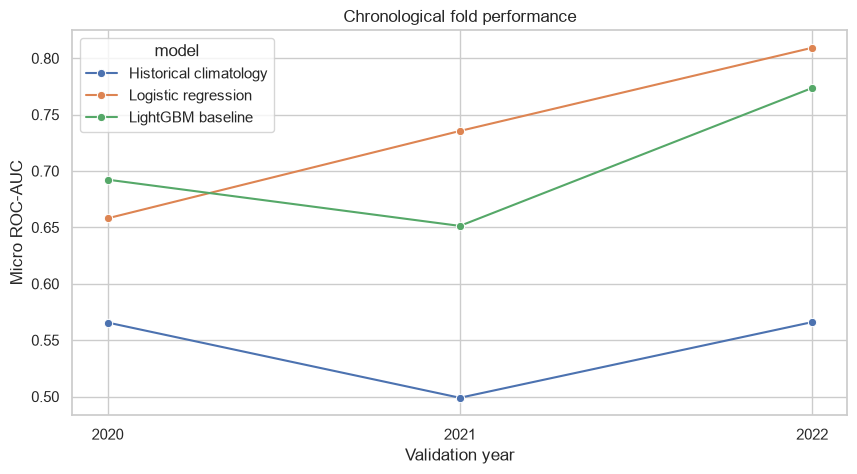

model,Historical climatology,LightGBM baseline,Logistic regression
unit,,,
Byrte_G1,0.4571,0.6890,0.8718
Haukeli_G1,0.5811,0.5933,0.6223
Hogga_G1,0.4680,0.7745,0.7646
Kjela_G1,0.4392,0.6945,0.8260
Lio_G1,0.5744,0.7338,0.7137
Songa_G1,0.3629,0.7776,0.8630
Tokke_G1,0.5199,0.7956,0.7890
Tokke_G2,0.4928,0.7580,0.7786
Tokke_G3,0.4831,0.7769,0.7774


In [12]:
summary = experiment_summary()
display(summary.style.format({
    "mean_auc": "{:.6f}",
    "worst_fold_auc": "{:.6f}",
    "best_fold_auc": "{:.6f}",
    "fold_std": "{:.6f}",
    "total_seconds": "{:.1f}",
}))

if experiment_rows:
    fold_scores = pd.DataFrame(experiment_rows)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.lineplot(
        data=fold_scores,
        x="validation_year",
        y="micro_auc",
        hue="model",
        marker="o",
        ax=ax,
    )
    ax.set(
        title="Chronological fold performance",
        xlabel="Validation year",
        ylabel="Micro ROC-AUC",
        xticks=[2020, 2021, 2022],
    )
    plt.show()

if per_unit_rows:
    unit_scores = pd.DataFrame(per_unit_rows)
    unit_summary = (
        unit_scores.groupby(["model", "unit"])["auc"]
        .mean().unstack("model")
    )
    display(unit_summary.style.format("{:.4f}"))


## 10. Train the first full LightGBM and create a Kaggle submission

Run this only after the fold results look sensible. The number of trees per unit is the median early-stopping iteration from the three folds. The model is then refitted on every labelled case from 2015–2022 and used for all 725 test cases.

This creates the first technical-control submission, not necessarily either of the final two selected submissions.


In [13]:
# Prerequisite: run the LightGBM validation cell first.
model_name = "LightGBM baseline"
if model_name not in best_iterations:
    raise RuntimeError("Run the LightGBM validation section before final training.")

all_train_case_ids = np.arange(N_TRAIN_CASES)
all_test_case_ids = np.arange(N_TRAIN_CASES, N_ALL_CASES)
train_rows = rows_for_cases(all_train_case_ids)
test_rows = rows_for_cases(all_test_case_ids)

X_train_full = X_all.iloc[train_rows]
X_test = X_all.iloc[test_rows]

test_prediction = np.empty(
    (N_TEST_CASES, len(units), HORIZON), dtype=np.float32
)
final_models = {}

for unit_idx, unit in enumerate(units):
    iterations = best_iterations[model_name][unit]
    if not iterations:
        raise RuntimeError(f"No best iterations stored for {unit}")

    final_n_estimators = max(50, int(np.median(iterations)))
    model = make_lgbm(n_estimators=final_n_estimators)
    y_train = target_cube[:, unit_idx, :].reshape(-1)
    model.fit(X_train_full, y_train)

    prediction = model.predict_proba(X_test)[:, 1]
    test_prediction[:, unit_idx, :] = prediction.reshape(
        N_TEST_CASES, HORIZON
    )
    final_models[unit] = model
    print(f"{unit:18s}: {final_n_estimators:4d} trees")


Hogga_G1          :   50 trees
Tokke_G1          :  156 trees
Tokke_G2          :   51 trees
Tokke_G3          :  141 trees
Tokke_G4          :   88 trees
Lio_G1            :   50 trees
Byrte_G1          :   50 trees
Vinje_G1          :   50 trees
Vinje_G2          :   59 trees
Vinje_G3          :  126 trees
Haukeli_G1        :   50 trees
Songa_G1          :   50 trees
Kjela_G1          :   50 trees
Vesle Kjela_G1    :   50 trees


In [14]:
submission_data = {"Run No": test_cases["Run No"].to_numpy()}
for unit_idx, unit in enumerate(units):
    for horizon in range(HORIZON):
        submission_data[f"result_committed_{unit}_t{horizon}"] = (
            test_prediction[:, unit_idx, horizon]
        )

submission = pd.DataFrame(submission_data)
submission = submission[sample_submission.columns]

assert submission.shape == sample_submission.shape
assert submission["Run No"].equals(sample_submission["Run No"])
assert not submission.isna().any().any()
assert np.isfinite(submission.iloc[:, 1:].to_numpy()).all()
assert submission.iloc[:, 1:].to_numpy().min() >= 0
assert submission.iloc[:, 1:].to_numpy().max() <= 1

submission_path = SUBMISSION_DIR/"lgbm_baseline.csv"
submission.to_csv(submission_path, index=False)

print("Saved:", submission_path.resolve())
print("Shape:", submission.shape)
print("Prediction range:",
      submission.iloc[:, 1:].to_numpy().min(),
      submission.iloc[:, 1:].to_numpy().max())
display(submission.iloc[:3, :8])


Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/lgbm_baseline.csv
Shape: (725, 2353)
Prediction range: 0.019638903 0.9885861


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.676719,0.561811,0.440302,0.474090,0.413349,0.355345,0.307310
1,2924,0.845042,0.845042,0.845042,0.845042,0.843365,0.847741,0.847741
2,2925,0.847741,0.847741,0.845042,0.845042,0.847741,0.847741,0.847741


## 11. What to do after running this notebook

1. Run sections 1–5 to build data, features, folds, and metric.
2. Run Historical climatology and record its scores.
3. Run Logistic regression and compare it with climatology.
4. Run LightGBM and inspect mean, worst-fold, per-year, and per-unit AUC.
5. If LightGBM is stable and best, run the full-training and submission cells.
6. Upload `submissions/lgbm_baseline.csv` to Kaggle as the first technical check.
7. Record the public score, but do not select the final model from that score alone.
8. Move to `04_tree_models.ipynb` and test feature blocks under these exact same folds:
   - raw/compact baseline;
   - weekly price rank and local windows;
   - water-value margins;
   - reservoir filling and inflow;
   - individual environmental constraints.
9. Keep a feature block only if it improves both mean AUC and does not materially damage the worst fold.

Do not overwrite the submission file associated with a Kaggle score. Save each serious experiment with a unique name and log its local and public scores.
